In [24]:
import random

import numpy as np

from mdpforge import Benchmark

DISCOUNT = 0.9
SIZE = "small"
PRECISION = 1e-3
REPEATS = 3
SEED = 0

TIMEOUT = 5  # Secondes par essai ; None désactive l'isolation en processus.

np.random.seed(SEED)
random.seed(SEED)

In [ ]:
bench = Benchmark()
bench.reset()
bench.add_solver("mdpforge_mpi", evaluation_precision=1e-2)
bench.add_solver("mdpforge_mpi", evaluation_precision=1e-1)
bench.add_mdp(category="navigation", size=SIZE)

ValueError: A solver named 'mdpforge_mpi' is already registered.

In [28]:
results = bench.run(
    discount=DISCOUNT,
    precision=PRECISION,
    repeats=REPEATS,
    seed=SEED,
    timeout=TIMEOUT,
    verbose=True,
)

1690_9_barto_3_0.1 / mdpforge_vi [1/3]: success (0.001 s)
1690_9_barto_3_0.1 / mdpforge_vi [2/3]: success (0.001 s)
1690_9_barto_3_0.1 / mdpforge_vi [3/3]: success (0.001 s)
1690_9_barto_3_0.1 / mdpforge_vi_relaxed [1/3]: success (0.001 s)
1690_9_barto_3_0.1 / mdpforge_vi_relaxed [2/3]: success (0.001 s)
1690_9_barto_3_0.1 / mdpforge_vi_relaxed [3/3]: success (0.001 s)
14283_4_cliff / mdpforge_vi [1/3]: success (0.031 s)
14283_4_cliff / mdpforge_vi [2/3]: success (0.030 s)
14283_4_cliff / mdpforge_vi [3/3]: success (0.030 s)
14283_4_cliff / mdpforge_vi_relaxed [1/3]: success (0.123 s)
14283_4_cliff / mdpforge_vi_relaxed [2/3]: success (0.123 s)
14283_4_cliff / mdpforge_vi_relaxed [3/3]: success (0.124 s)
24194_5_deep_sea_treasure_v1_depth62_current0.15 / mdpforge_vi [1/3]: success (0.021 s)
24194_5_deep_sea_treasure_v1_depth62_current0.15 / mdpforge_vi [2/3]: success (0.021 s)
24194_5_deep_sea_treasure_v1_depth62_current0.15 / mdpforge_vi [3/3]: success (0.020 s)
24194_5_deep_sea_treas

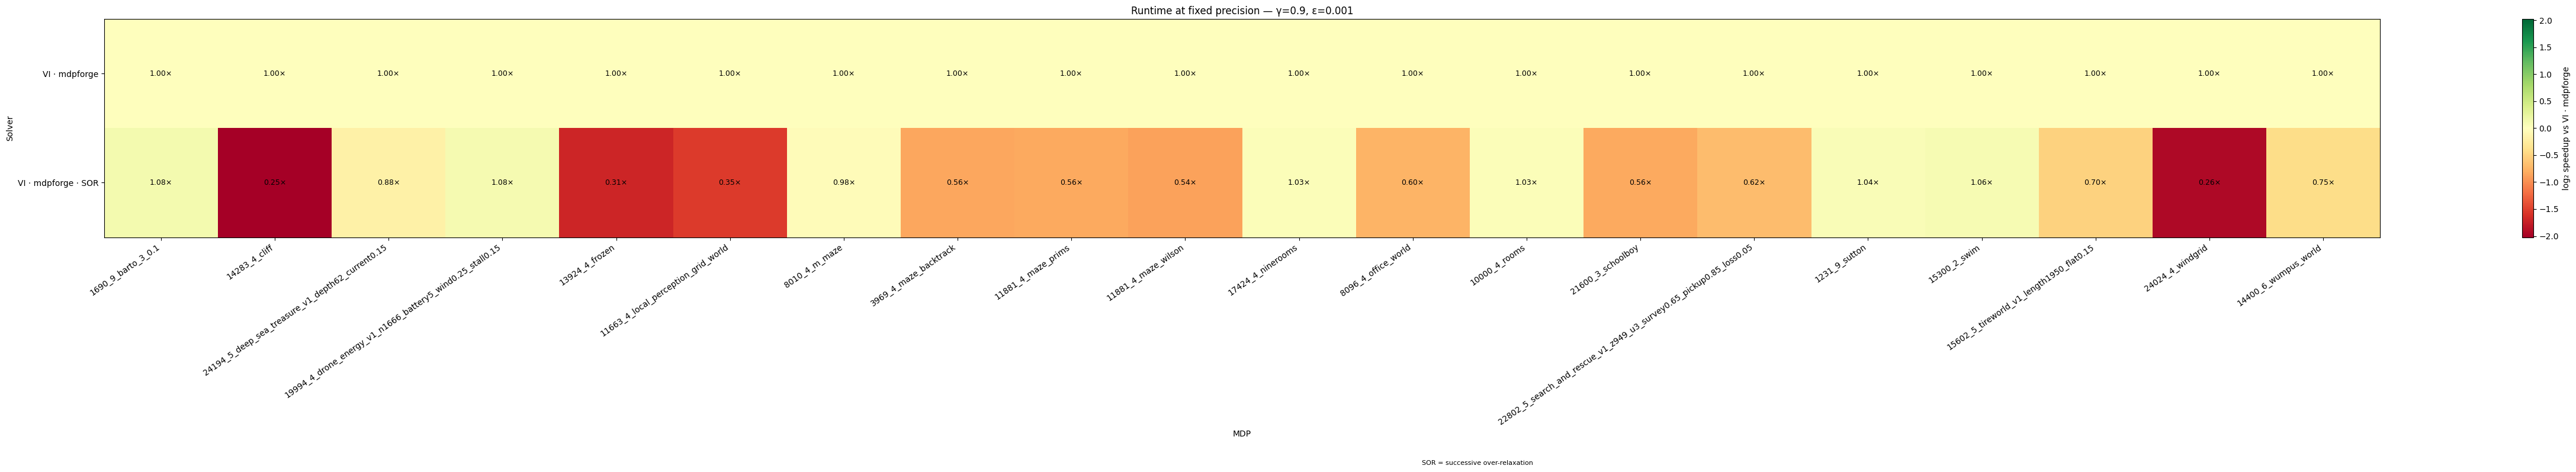

(<Figure size 5000x800 with 2 Axes>,
 <Axes: title={'center': 'Runtime at fixed precision — γ=0.9, ε=0.001'}, xlabel='MDP', ylabel='Solver'>)

In [29]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(50, 8))
results.plot_heat(ax=ax, reference="mdpforge_vi")

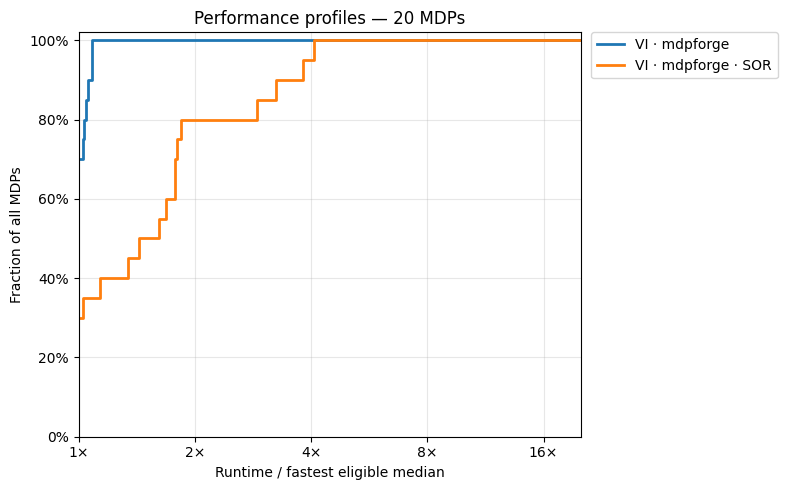

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Performance profiles — 20 MDPs'}, xlabel='Runtime / fastest eligible median', ylabel='Fraction of all MDPs'>)

In [30]:
results.plot_performance_profile(max_factor=20)

In [7]:
results.summary()

,model,solver,n_success,n_trials,median_runtime,complete
0,620_10_block_0.85_10,mdpforge_aggmpi,3,3,0.022663,True
1,620_10_block_0.85_10,mdpforge_aggqvi,3,3,0.019532,True
2,620_10_block_0.85_10,mdpforge_aggvi,3,3,0.020862,True
3,620_10_block_0.85_10,mdpforge_bertsekas,3,3,0.025002,True
4,620_10_block_0.85_10,mdpforge_chen,3,3,0.094181,True
...,...,...,...,...,...,...
86,20400_2_unichain,mdpforge_pi,3,3,0.005835,True
87,20400_2_unichain,mdpforge_vi,3,3,0.032270,True
88,20400_2_unichain,mdpforge_vi_reward_init,3,3,0.039717,True
89,20400_2_unichain,mdpforge_vi_span,3,3,0.029693,True


In [8]:
results.export_csv()

WindowsPath('c:/Users/orsof/github/mdpforge/notebooks/artifacts/benchmark/bench_2026-10-25_17-49-47_293799.csv')